# 03 — Customers: RFM, Segmentation and Retention

**CRISP-DM phase:** Data Preparation → Modeling (descriptive / unsupervised)

**Business questions**
1. Who are the most valuable customers, and how concentrated is revenue?
2. Which customer segments exist (rule-based RFM vs K-Means clustering)?
3. How many customers come back, and when (cohort retention)?
4. Does a bad first experience (late delivery, bad review) stop customers from coming back?

A **customer** is a person: `customer_unique_id` (the `customer_id` column changes on every order).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
OUT_DIR = PROJECT_ROOT / "data" / "processed"

GREY, RED, BLUE, DARK, GREEN = "#B0B7BF", "#D1495B", "#2E86AB", "#2B2D42", "#81B29A"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "font.size": 10,
})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


orders = pd.read_parquet(OUT_DIR / "orders.parquet")
print(f"{len(orders):,} delivered orders from {orders['customer_unique_id'].nunique():,} customers")

96,470 delivered orders from 93,350 customers


## 1. RFM table

- **Recency**: days since the last purchase, measured from a *snapshot date* (the day after the last order in the data — not today, or every customer would look inactive).
- **Frequency**: number of orders.
- **Monetary**: total amount paid.

In [2]:
snapshot = orders["purchase_ts"].max().normalize() + pd.Timedelta(days=1)

rfm = orders.groupby("customer_unique_id").agg(
    first_purchase=("purchase_ts", "min"),
    last_purchase=("purchase_ts", "max"),
    frequency=("order_id", "nunique"),
    monetary=("paid", "sum"),
    customer_state=("customer_state", "first"),
    avg_review=("review_score", "mean"),
)
rfm["recency_days"] = (snapshot - rfm["last_purchase"]).dt.days

print(f"Snapshot date: {snapshot.date()}")
print(f"Customers: {len(rfm):,}")
# Cross-check with sql/04_customers.sql (query 4.3): avg recency 237, avg monetary 165.20.
# Tiny differences are expected: the parquet excludes 8 delivered orders with no delivery date.
rfm[["recency_days", "frequency", "monetary"]].describe().round(1)

Snapshot date: 2018-08-30
Customers: 93,350


,recency_days,frequency,monetary
count,93350.0,93350.0,93350.0
mean,237.5,1.0,165.2
std,152.6,0.2,226.3
min,0.0,1.0,0.0
25%,114.0,1.0,63.0
50%,219.0,1.0,107.8
75%,346.0,1.0,182.5
max,713.0,15.0,13664.1


In [3]:
# How concentrated is revenue?
sorted_m = rfm["monetary"].sort_values(ascending=False)
cum_share = sorted_m.cumsum() / sorted_m.sum()
top10 = cum_share.iloc[int(len(cum_share) * 0.10) - 1]
top20 = cum_share.iloc[int(len(cum_share) * 0.20) - 1]
print(f"Top 10% of customers generate {top10:.0%} of revenue")
print(f"Top 20% of customers generate {top20:.0%} of revenue")

Top 10% of customers generate 38% of revenue
Top 20% of customers generate 54% of revenue


## 2. RFM scores and rule-based segments

Classic RFM splits each metric into **quintiles** (5 equal-sized groups, scored 1–5). That fails for Frequency here, because 97% of customers have exactly one order — there are no 5 distinct groups to split into:

In [4]:
print(rfm["frequency"].value_counts().sort_index().head(6))
try:
    pd.qcut(rfm["frequency"], 5)
except ValueError as err:
    print("\nqcut on frequency fails:", err)

frequency
1    90549
2     2573
3      181
4       28
5        9
6        5
Name: count, dtype: int64

qcut on frequency fails: Bin edges must be unique: Index([1.0, 1.0, 1.0, 1.0, 1.0, 15.0], dtype='float64', name='frequency').
You can drop duplicate edges by setting the 'duplicates' kwarg


**Adaptation:** score Recency and Monetary with quintiles, and treat Frequency as a yes/no flag (**repeat customer** = 2+ orders). Segments are then defined with simple, explainable rules.

In [5]:
# Recency: FEWER days = better, so the labels go 5 → 1
rfm["R"] = pd.qcut(rfm["recency_days"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["repeat"] = rfm["frequency"] >= 2


def rfm_segment(row):
    if row["repeat"]:
        return "Loyal" if row["R"] >= 3 else "Lapsed loyal"
    if row["R"] >= 4:
        return "Recent big spender" if row["M"] >= 4 else "Recent"
    return "At-risk big spender" if row["M"] >= 4 else "Hibernating"


rfm["segment"] = rfm.apply(rfm_segment, axis=1)

SEGMENT_ORDER = ["Loyal", "Lapsed loyal", "Recent big spender",
                 "Recent", "At-risk big spender", "Hibernating"]
segments = (
    rfm.groupby("segment")
    .agg(
        customers=("monetary", "size"),
        revenue=("monetary", "sum"),
        avg_spend=("monetary", "mean"),
        avg_recency_days=("recency_days", "mean"),
        avg_review=("avg_review", "mean"),
    )
    .reindex(SEGMENT_ORDER)
)
segments["customer_share"] = segments["customers"] / segments["customers"].sum()
segments["revenue_share"] = segments["revenue"] / segments["revenue"].sum()
segments.round(2)

,customers,revenue,avg_spend,avg_recency_days,avg_review,customer_share,revenue_share
segment,,,,,,,
Loyal,1819,577138.08,317.28,131.97,4.20,0.02,0.04
Lapsed loyal,982,287219.13,292.48,382.52,4.21,0.01,0.02
Recent big spender,14497,4380913.92,302.19,91.48,4.13,0.16,0.28
Recent,21842,1593049.53,72.94,89.77,4.25,0.23,0.10
At-risk big spender,20602,6147428.02,298.39,335.95,4.04,0.22,0.40
Hibernating,33608,2435334.17,72.46,337.59,4.17,0.36,0.16


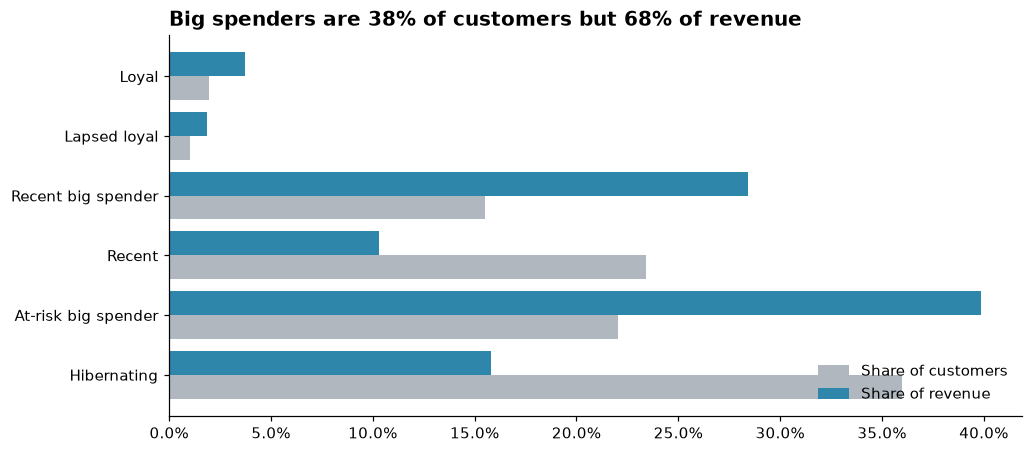

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(segments))
ax.barh(y + 0.2, segments["customer_share"], height=0.4, color=GREY, label="Share of customers")
ax.barh(y - 0.2, segments["revenue_share"], height=0.4, color=BLUE, label="Share of revenue")
ax.set_yticks(y, segments.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
big = segments.loc[["Recent big spender", "At-risk big spender"]].sum()
ax.set_title(f"Big spenders are {big['customer_share']:.0%} of customers "
             f"but {big['revenue_share']:.0%} of revenue")
ax.legend(frameon=False, loc="lower right")
save(fig, "07_rfm_segments")
plt.show()

## 3. K-Means clustering

K-Means groups customers so that each customer is close to the centre of its cluster. Steps:
1. **Features**: recency, *log* of monetary (spending is very skewed — a few customers spend 50x the median — and the log stops them from dominating), and the repeat flag.
2. **Standardise** (mean 0, std 1): K-Means uses distances, so features on bigger scales (days vs. flags) would otherwise dominate.
3. **Choose k** with the elbow (inertia) and the silhouette score (how well separated clusters are; higher is better), on k = 2…8.

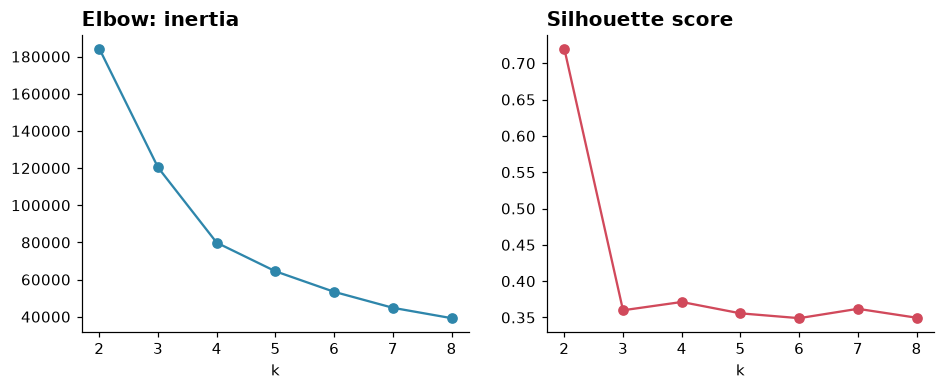

,inertia,silhouette
k,,
2,184245.974,0.720
3,120328.932,0.360
4,79842.234,0.371
5,64450.673,0.356
6,53398.245,0.349
7,44805.238,0.362
8,39230.286,0.350


In [7]:
features = pd.DataFrame({
    "recency_days": rfm["recency_days"],
    "log_monetary": np.log1p(rfm["monetary"]),
    "repeat": rfm["repeat"].astype(int),
})
X = StandardScaler().fit_transform(features)

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X), size=10_000, replace=False)  # silhouette is slow on 93k rows

results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    sil = silhouette_score(X[sample_idx], km.labels_[sample_idx])
    results.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
results = pd.DataFrame(results).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(results.index, results["inertia"], marker="o", color=BLUE)
axes[0].set_title("Elbow: inertia")
axes[0].set_xlabel("k")
axes[1].plot(results.index, results["silhouette"], marker="o", color=RED)
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
save(fig, "08_kmeans_choose_k")
plt.show()
results.round(3)

k = 2 has the highest silhouette, but it only splits "repeat" vs "one-time" customers, which we already know. We therefore choose the best silhouette among **k = 3…6**: fewer than 3 clusters is too coarse to act on, and more than 6 is hard for a marketing team to use. This is a business decision informed by the metric, not dictated by it.

In [8]:
best_k = results.loc[3:6, "silhouette"].idxmax()
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X)
rfm["cluster"] = kmeans.labels_

profile = rfm.groupby("cluster").agg(
    customers=("monetary", "size"),
    repeat_share=("repeat", "mean"),
    median_recency_days=("recency_days", "median"),
    median_spend=("monetary", "median"),
    revenue=("monetary", "sum"),
    avg_review=("avg_review", "mean"),
)
profile["revenue_share"] = profile["revenue"] / profile["revenue"].sum()


def name_cluster(row):
    """Readable name from the cluster's profile, compared with all customers."""
    if row["repeat_share"] > 0.5:
        return "Repeat buyers"
    if row["median_spend"] > rfm["monetary"].median():
        return "High spenders"   # spend, not recency, is what defines this group
    recency = "Recent" if row["median_recency_days"] < rfm["recency_days"].median() else "Dormant"
    return f"{recency} · low spend"


profile["name"] = profile.apply(name_cluster, axis=1)
rfm["cluster_name"] = rfm["cluster"].map(profile["name"])
print(f"k = {best_k}")
profile.sort_values("revenue", ascending=False).round(2)

k = 4


,customers,repeat_share,median_recency_days,median_spend,revenue,avg_review,revenue_share,name
cluster,,,,,,,,
0,27815,0.0,169.0,210.60,8858821.64,4.04,0.57,High spenders
1,27066,0.0,417.0,98.16,3234290.18,4.22,0.21,Dormant · low spend
2,35668,0.0,147.0,66.00,2463613.82,4.19,0.16,Recent · low spend
3,2801,1.0,199.0,225.55,864357.21,4.20,0.06,Repeat buyers


In [9]:
# How do the K-Means clusters line up with the rule-based segments?
pd.crosstab(rfm["segment"], rfm["cluster_name"], normalize="index").reindex(SEGMENT_ORDER).round(2)

cluster_name,Dormant · low spend,High spenders,Recent · low spend,Repeat buyers
segment,,,,
Loyal,0.00,0.00,0.00,1.0
Lapsed loyal,0.00,0.00,0.00,1.0
Recent big spender,0.00,0.99,0.01,0.0
Recent,0.00,0.02,0.98,0.0
At-risk big spender,0.40,0.60,0.00,0.0
Hibernating,0.56,0.02,0.42,0.0


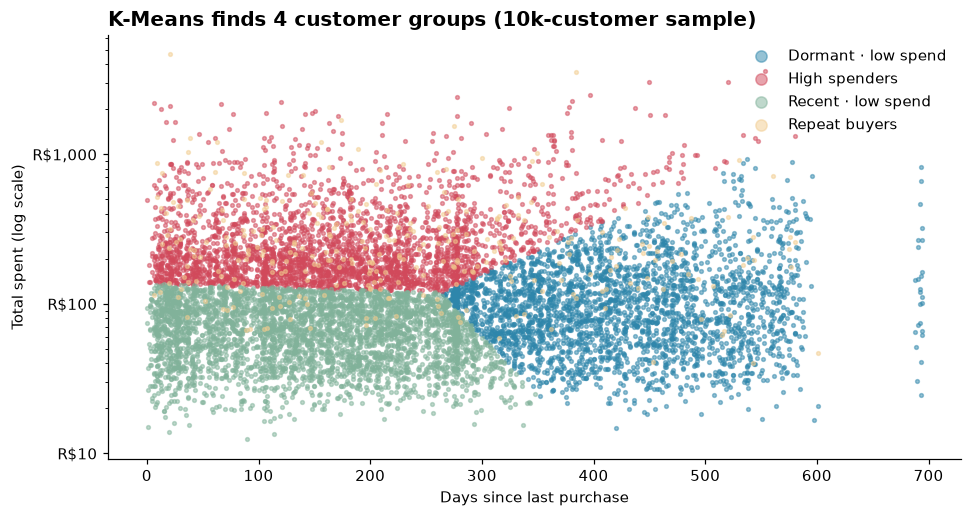

In [10]:
plot_sample = rfm.iloc[sample_idx]
palette = [BLUE, RED, GREEN, "#F2CC8F", "#6D597A", GREY]

fig, ax = plt.subplots(figsize=(10, 5))
for i, (name, grp) in enumerate(plot_sample.groupby("cluster_name")):
    ax.scatter(grp["recency_days"], grp["monetary"], s=6, alpha=0.5,
               color=palette[i % len(palette)], label=name)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("R${x:,.0f}"))
ax.set_xlabel("Days since last purchase")
ax.set_ylabel("Total spent (log scale)")
ax.set_title(f"K-Means finds {best_k} customer groups (10k-customer sample)")
legend = ax.legend(frameon=False, markerscale=3, loc="upper right")
save(fig, "09_kmeans_clusters")
plt.show()

## 4. Cohort retention

A **cohort** is the group of customers who made their first purchase in the same month. For each cohort we measure the % who bought again *k* months later.

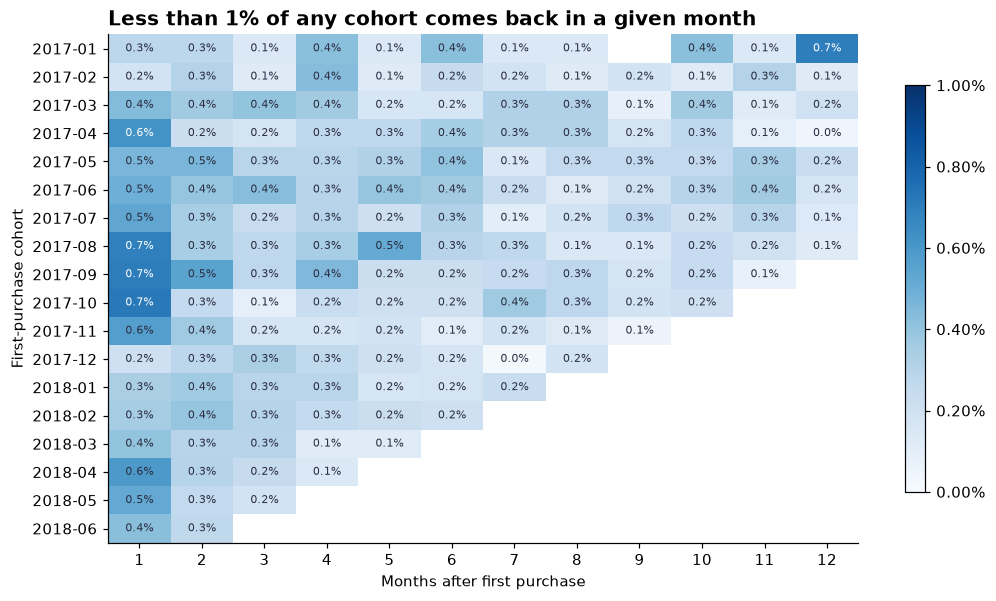

Average month-1 retention: 0.47%
Average month-1..6 retention per month: 0.31%


In [11]:
c = orders[["customer_unique_id", "purchase_ts"]].copy()
# Month as a single integer (year*12 + month) makes month differences simple subtraction
c["month_idx"] = c["purchase_ts"].dt.year * 12 + c["purchase_ts"].dt.month
c["cohort_idx"] = c.groupby("customer_unique_id")["month_idx"].transform("min")
c["months_after"] = c["month_idx"] - c["cohort_idx"]
c["cohort"] = c.groupby("customer_unique_id")["purchase_ts"].transform("min").dt.to_period("M")

active = c.groupby(["cohort", "months_after"])["customer_unique_id"].nunique().unstack()
cohort_size = active[0]
retention = active.div(cohort_size, axis=0)

# Cohorts Jan 2017 – Jun 2018, first 12 months after the first purchase
retention = retention.loc["2017-01":"2018-06", 1:12]

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(retention.values, cmap="Blues", aspect="auto", vmin=0, vmax=0.01)
ax.set_xticks(range(retention.shape[1]), retention.columns)
ax.set_yticks(range(retention.shape[0]), [str(p) for p in retention.index])
ax.set_xlabel("Months after first purchase")
ax.set_ylabel("First-purchase cohort")
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        v = retention.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.006 else DARK)
ax.set_title("Less than 1% of any cohort comes back in a given month")
fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0), shrink=0.8)
save(fig, "10_cohort_retention")
plt.show()

print(f"Average month-1 retention: {retention[1].mean():.2%}")
print(f"Average month-1..6 retention per month: {retention.loc[:, 1:6].stack().mean():.2%}")

## 5. Does a bad first experience stop customers from coming back?

**Design (avoiding right-censoring bias):**
- Take each customer's **first** order.
- Only customers whose first order was **before March 2018**, so everyone had a full 180 days to come back before the data ends.
- **Repeat** = another order between 1 and 180 days after the first. Orders on the same day are excluded, because they are usually one shopping session split into several orders, not a return visit.

In [12]:
first = (
    orders.sort_values("purchase_ts")
    .drop_duplicates("customer_unique_id", keep="first")   # first order per customer
    .set_index("customer_unique_id")
)
first = first[first["purchase_ts"] < "2018-03-01"]

later = orders.merge(first[["purchase_ts"]].rename(columns={"purchase_ts": "first_ts"}),
                     left_on="customer_unique_id", right_index=True)
gap = later["purchase_ts"] - later["first_ts"]
returned = later.loc[(gap > pd.Timedelta(days=1)) & (gap <= pd.Timedelta(days=180)),
                     "customer_unique_id"].unique()
first["returned_180d"] = first.index.isin(returned)

print(f"Customers analysed: {len(first):,}")
print(f"Returned within 180 days: {first['returned_180d'].mean():.2%}")

Customers analysed: 55,523
Returned within 180 days: 1.95%


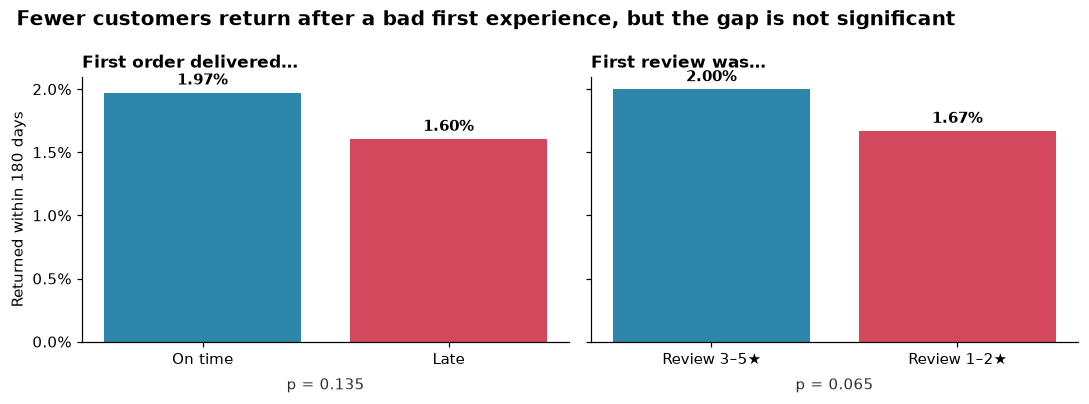

On time    0.0197
Late       0.0160
Name: returned_180d, dtype: float64 chi-square p = 0.135

Review 3–5★    0.0200
Review 1–2★    0.0167
Name: returned_180d, dtype: float64 chi-square p = 0.065


In [13]:
def compare(flag_col, labels):
    """Return rate for customers with/without a flag on their first order, plus a chi-square test."""
    df = first.dropna(subset=[flag_col])
    table = pd.crosstab(df[flag_col], df["returned_180d"])
    _, p, _, _ = stats.chi2_contingency(table)
    rates = df.groupby(flag_col)["returned_180d"].mean()
    rates.index = [labels[bool(i)] for i in rates.index]
    return rates, p


late_rates, p_late = compare("is_late", {False: "On time", True: "Late"})
review_rates, p_review = compare("is_bad_review", {False: "Review 3–5★", True: "Review 1–2★"})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, rates, p, title in [
    (axes[0], late_rates, p_late, "First order delivered…"),
    (axes[1], review_rates, p_review, "First review was…"),
]:
    bars = ax.bar(rates.index, rates.values, color=[BLUE, RED])
    ax.bar_label(bars, labels=[f"{v:.2%}" for v in rates.values], padding=3, fontweight="bold")
    ax.set_title(title, fontsize=11)
    ax.text(0.5, -0.18, "p < 0.001" if p < 0.001 else f"p = {p:.3f}",
            transform=ax.transAxes, ha="center", color=DARK)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
axes[0].set_ylabel("Returned within 180 days")
fig.suptitle("Fewer customers return after a bad first experience, but the gap is not significant",
             x=0.02, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "11_repeat_by_first_experience")
plt.show()

print(late_rates.round(4), f"chi-square {('p < 0.001' if p_late < 0.001 else f'p = {p_late:.3f}')}\n")
print(review_rates.round(4), f"chi-square {('p < 0.001' if p_review < 0.001 else f'p = {p_review:.3f}')}")

## 6. Save the segments for the dashboard

In [14]:
out = rfm.reset_index()[[
    "customer_unique_id", "customer_state", "first_purchase", "last_purchase",
    "recency_days", "frequency", "monetary", "avg_review",
    "R", "M", "repeat", "segment", "cluster_name",
]]
out.to_parquet(OUT_DIR / "customer_segments.parquet", index=False)
print(f"Saved {len(out):,} customers → data/processed/customer_segments.parquet")

Saved 93,350 customers → data/processed/customer_segments.parquet


## Key findings

1. **Revenue is concentrated.** The top 10% of customers bring 38% of revenue and the top 20% bring 54%.
2. **Almost nobody is loyal.** Only 3% of customers ("Loyal" + "Lapsed loyal") have 2+ orders. Classic RFM quintiles break on Frequency, so we used Frequency as a repeat flag.
3. **The biggest opportunity is the "At-risk big spender" segment:** 22% of customers who generated **40% of revenue** but have not bought for ~11 months on average. It is the natural target for a win-back campaign.
4. **K-Means (k = 4) confirms the rule-based picture** with four groups: High spenders (57% of revenue), Dormant · low spend, Recent · low spend and Repeat buyers. The clusters line up closely with the RFM segments (see the crosstab), so the simpler, explainable rules are good enough for the business.
5. **Retention is extremely low:** on average 0.47% of a cohort buys again in the month after their first purchase, and ~0.3% per month over the first six months. Only **1.95%** return within 180 days.
6. **A bad first experience shows a small, non-significant drop in returns:** 1.60% vs 1.97% after a late first order (p = 0.135), and 1.67% vs 2.00% after a bad first review (p = 0.065). The direction matches the Phase 2 story, but with a ~2% base rate the data cannot prove it. **Retention is low for everyone**, so fixing delivery alone will not fix retention.

**Business implications**
- Prioritise a **win-back campaign** for At-risk big spenders (highest revenue at stake).
- Since even happy customers rarely return, retention needs **active levers** (post-purchase emails, vouchers for a second order, category cross-sell), not just better delivery.
- Delivery quality still matters for **reviews and reputation** (Phase 2), which drive new-customer acquisition.